# Numpy and  Matplotlib

## Numpy

NumPy is a linear algebra library in Python, with computationally expensive methods written in FORTRAN for speed.

* The reference manual is at <https://numpy.org/doc/stable/>.
* A nice tutorial can be found at <https://numpy.org/doc/stable/user/quickstart.html>
* or: <https://cs231n.github.io/python-numpy-tutorial/>
* If you already know Matlab, a comparison is at <https://numpy.org/doc/stable/user/numpy-for-matlab-users.html>

This notebook only introduces you to the basics, so feel free to study additional resources if you want to master it.

For example try yourself on the 100 numpy problems by Nicolas Rougier [github](https://github.com/rougier/numpy-100/tree/master), [colab](https://colab.research.google.com/github/rougier/numpy-100/blob/master/100_Numpy_exercises.ipynb).

### Importing libraries

To import a library in Python, you only need to use the keyword `import` at the beginning of your script / notebook (or more exactly, before you use it).

```python
import numpy
```

Think of it as the equivalent of `#include <numpy.h>` in C/C++ (if you know Java, you will not be shocked). You can then use the functions and objects provided by the library using the namespace of the library:

```python
x = numpy.array([1, 2, 3])
```

If you do not want to type `numpy.` everytime, and if you are not afraid that numpy redefines any important function, you can also simply import every definition declared by the library in your current namespace with:

```python
from numpy import *
```

and use the objects directly:

```python
x = array([1, 2, 3])
```

However, it is good practice to give an alias to the library when its name is too long (numpy is still okay, but think of matplotlib...):

```python
import numpy as np
```

You can then use the objects like this:

```python
x = np.array([1, 2, 3])
```

Remember that you can get help on any NumPy function:

```python
help(np.array)
help(np.ndarray.transpose)
```

In [ ]:
import numpy as np

### Vectors and matrices

The basic object in NumPy is an **array** with d-dimensions (1D = vector, 2D = matrix, 3D or more = tensor). They can store either integers or floats, using various precisions.

In order to create a vector of three floats, you simply have to build an `array()` object by providing a list of floats as input:

```python
A = np.array( [ 1., 2., 3.] )
```

Matrices should be initialized with a list of lists.  For a 3x4 matrix of 8 bits unsigned integers, it is:

```python
B = np.array( [
    [ 1, 2, 3, 4],
    [ 5, 6, 7, 8],
    [ 4, 3, 2, 1]
  ] , dtype=np.uint8)
```

Most of the time, you won't care about the type (the default floating-point precision is what you want for machine learning), but if you need it, you can always specify it with the parameter `dtype={int32, uint16, float64, ...}`. Note that even if you pass integers to the array (`np.array( [ 1, 2, 3] )`), they will be converted to floats by default.

The following attributes of an array can be accessed:

- `A.shape` : returns the shape of the vector `(n,)` or matrix `(m, n)`.

- `A.size` : returns the total number of elements in the array.

- `A.ndim` : returns the number of dimensions of the array (vector: 1, matrix:2).

- `A.dtype.name` : returns the type of data stored in the array (int32, uint16, float64...).

**Q:** Define the two arrays $A$ and $B$ from above and print those attributes. Modify the arrays (number of elements, type) and observe how they change.

*Hint:* you can print an array just like any other Python object.

In [ ]:
import numpy as np

A = np.array( [ 1., 2., 3.] )

B = np.array( [
    [ 1, 2, 3, 4],
    [ 5, 6, 7, 8],
    [ 4, 3, 2, 1]
  ] , dtype=np.uint8)

print(A.shape)
print(B.shape)
print(A.size, B.size)

print(A.ndim, B.ndim) #return the demension of A, and B

print(A.dtype.name, B.dtype.name) # return the type of data stored in the arryay like float64, uint8,uint16


(3,)
(3, 4)
3 12
1 2
float64 uint8


Internally, the values are stored sequentially as a vector, even if your array has more than one dimension. The apparent shape is just used for mathematical operations. You can **reshape** a matrix very easily with the `reshape()` method:

```python
B = np.array( [
    [ 1, 2, 3, 4],
    [ 5, 6, 7, 8],
    [ 4, 3, 2, 1]
]) # B has 3 rows, 4 columns

C = B.reshape((6, 2)) # C has 6 rows, 2 columns
```

The only thing to respect is that the total number of elements must be the same. Beware also of the order in which the elements will be put.

**Q:** Create a vector with 8 elements and reshape it into a 2x4 matrix.

In [ ]:
A = np.array([1, 2, 3, 4, 5, 6, 7, 8])

B = A.reshape((2, 4))

print(B)

[[1 2 3 4]
 [5 6 7 8]]


### Initialization of an array

Providing a list of values to `array()` would be tedious for large arrays. Numpy offers constructors that allow to construct simply most vectors or matrices.

`np.zeros(shape)` creates an array of shape `shape` filled with zeros. Note: if you give a single integer for the shape, it will be interpreted as a vector of shape `(d,)`.

`np.ones(shape)` creates an array of shape `shape` filled with ones.

`np.full(shape, val)` creates an array of shape `shape` filled with `val`.

`np.eye(n)` creates a diagonal matrix of shape `(n, n)`.

`np.arange(a, b)` creates a vector of integers whose value linearly increase from `a` to `b` (excluded).

`np.linspace(a, b, n)` creates a vector of `n` values evenly distributed between `a` and `b` (included).


**Q:** Create and print:

* a 2x3 matrix filled with zeros.
* a vector of 12 elements initialized to 3.14.
* a vector of 11 elements whose value linearly increases from 0.0 to 10.0.
* a vector of 11 elements whose value linearly increases from 10 to 20.

In [ ]:
A = np.zeros((2, 3))
B = np.full(12, 3.14)
C = np.linspace(0.0, 10.0, 11)
D = np.linspace(10, 20, 11)

print(A, B, C, D, sep="\n")

[[0. 0. 0.]
 [0. 0. 0.]]
[3.14 3.14 3.14 3.14 3.14 3.14 3.14 3.14 3.14 3.14 3.14 3.14]
[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
[10. 11. 12. 13. 14. 15. 16. 17. 18. 19. 20.]


### Random distributions

In many cases, it is useful to initialize a vector or matrix with random values. **Random number generators** (rng) allows to draw numbers from any probability distribution (uniform, normal, etc.) using pseudo-random methods.

In numpy versions before 1.16, the `numpy.random` module had direct methods allowing to initialize arrays:

```python
A = np.random.uniform(-1.0, 1.0, (10, 10)) # a 10x10 matrix with values uniformly taken between -1 and 1
```

Since numpy 1.16, this method has been deprecated in favor of a more explicit initialization of the underlying rng:

```python
rng = np.random.default_rng()
A = rng.uniform(-1.0, 1.0, (10, 10))
```

The advantages of this new method (reproducibility, parallel seeds) will not matter for these exercises, but let's take good habits already.

The generator has many built-in methods, covering virtually any useful probability distribution. Read the documentation of the random generator:

<https://numpy.org/doc/stable/reference/random/generator.html>

**Q:** Create:

* A vector of 20 elements following a normal distribution with mean 2.0 and standard devation 3.0.
* A 10x10 matrix whose elements come from the exponential distribution with $\beta = 2$.
* A vector of 10 integers randomly chosen between 1 and 100 (hint: involves `arange` and `rng.choice`).

In [ ]:
import numpy as np

rng = np.random.default_rng()

A = rng.uniform(2.0, 3.0, 20)
B = rng.exponential(2.0, (10, 10))
C = rng.choice(np.arange(1, 101), size=10)

print(A, B, C, sep="\n\n" )

[2.98973239 2.85732474 2.85439065 2.31763981 2.31290933 2.14018984
 2.72453726 2.930664   2.61830189 2.09640002 2.35228771 2.46210782
 2.05302884 2.42505689 2.45372238 2.61316592 2.73474046 2.32809688
 2.44311094 2.19579845]

[[2.81173015e+00 5.23762227e+00 3.95585070e-01 1.43167990e+00
  4.95134564e+00 1.75777792e-01 2.86873784e-01 8.60518437e-01
  2.82977772e+00 1.39952353e+00]
 [8.18078306e-01 1.42883990e+00 1.39894851e+00 7.27752390e+00
  1.01883720e-01 4.05045867e+00 1.65350331e+00 1.81288681e+00
  6.62265258e+00 2.31692929e+00]
 [1.28259662e+00 2.06988071e+00 1.31016972e+00 2.30215202e+00
  5.96188340e-01 5.12577846e-01 4.76888499e-01 2.23960877e+00
  3.02863060e+00 5.16423128e+00]
 [3.26742574e+00 3.14406171e-01 1.38346655e+00 3.51042670e-01
  6.38710802e-02 4.13786541e+00 5.03013722e-01 4.30489047e+00
  9.28295821e-01 1.36978754e+00]
 [1.58262949e+00 2.44943837e+00 5.51166378e-01 1.22520743e+00
  5.84419137e-01 1.49250161e+00 3.21319888e-01 1.64057227e+00
  1.19319856e+00 3.621

### Manipulation of matrices: indices, slices

To access a particular element of a matrix, you can use the usual Python list style (the first element has a rank of 0), once per dimension:

```python
A = np.array(
    [
        [ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]
    ]
)

x = A[0, 2] # The element on the first row and third column
```

For matrices, the first index represents the rows, the second the columns. [0, 2] represents the element at the first row, third column.

**Q:** Define this matrix and replace the element `12` by a zero using indices:

In [ ]:
import numpy as np

A = np.array(
    [
        [ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]
    ]
)

x = A[0, 2] # The element on the first row and third column

A[2, 3] = 0  ##
print(A)



[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11  0]]


It is possible to access complete row or columns of a matrix using **slices**. The `:` symbol is a shortcut for "everything":

```python
b = A[:, 2] # third column
c = A[0, :] # first row
```

**Q:** Set the fourth column of A to 1.

In [ ]:
A[:, 3] = 1

print(A)

[[ 1  2  3  1]
 [ 5  6  7  1]
 [ 9 10 11  1]]


As for python lists, you can specify a range `start:stop` to get only a subset of a row/column (beware, stop is excluded):

```python
d = A[0, 1:3] # second and third elements of the first row
e = A[1, :2] # first and second elements of the second row
```

In [ ]:
import numpy as np

A = np.array(
    [
        [ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]
    ]
)
A[1, 1:3] = 100 # second row, take the index 1 and 2, excluded 3;

A[2, :3] = 9999 # third row, first three elements take 9999

print(A)

[[   1    2    3    4]
 [   5  100  100    8]
 [9999 9999 9999   12]]


You can use boolean arrays to retrieve indices:

```python
A = np.array(
    [ [ -2,  2,  1, -4],
      [  3, -1, -5, -3] ])

negatives = A < 0 # Boolean array where each element is True when the condition is met.
A[negatives] = 0 # All negative elements of A (where the boolean matrix is True) will be set to 0
```

A simpler way to write it is:

```python
A[A < 0] = 0
```

**Q:** print A, negatives and A again after the assignment:

In [8]:
import numpy as np

A = np.array(
    [ [ -2,  2,  1, -4],
      [  3, -1, -5, -3] ])

print(A)

negatives = A < 0
print(negatives)

print(A[A < 0])

A[negatives] = 0
print(A)

[[-2  2  1 -4]
 [ 3 -1 -5 -3]]
[[ True False False  True]
 [False  True  True  True]]
[-2 -4 -1 -5 -3]
[[0 2 1 0]
 [3 0 0 0]]


### Basic linear algebra

Let's first define some matrices:

In [9]:
A = np.array( [ [ 1, 2, 3, 4],
                [ 5, 6, 7, 8] ])

B = np.array( [ [ 1, 2],
                [ 3, 4],
                [ 5, 6],
                [ 7, 8] ])

C = np.array( [ [  1,  2,  3,  4],
                [  5,  6,  7,  8],
                [  9,  0,  1,  1],
                [ 13,  7,  2,  6] ])

#### Transpose a matrix

A matrix can be transposed with the `transpose()` method or the `.T` shortcut:

```python
D = A.transpose()
E = A.T # equivalent
```

**Q:** Try it:

In [12]:
D = A.transpose()
E = A.T

print(A, E, sep='\n')

[[1 2 3 4]
 [5 6 7 8]]
[[1 5]
 [2 6]
 [3 7]
 [4 8]]


`transpose()` does not change `A`, it only returns a transposed copy. To transpose `A` definitely, you have to use the assigment `A = A.T`

#### Multiply two matrices

There are two manners to multiply matrices:

- element-wise: Two arrays of **exactly** the same shape can be multiplied *element-wise* by using the `*` operator:

```python
D = A * B
```

- algebrically: To perform a **matrix multiplication**, you have to use the `dot()` method. Beware: the dimensions must match! `(m, n) * (n, p) = (m, p)`

```python
E = np.dot(A,  B)
```

**Q:** Use the matrices `A` and `B` previously defined and multiply them element-wise and algebrically. You may have to transpose one of them.

In [14]:
A = np.array( [ [ 1, 2, 3, 4],
                [ 5, 6, 7, 8] ])

B = np.array( [ [ 1, 2],
                [ 3, 4],
                [ 5, 6],
                [ 7, 8] ])

C = np.array( [ [  1,  2,  3,  4],
                [  5,  6,  7,  8],
                [  9,  0,  1,  1],
                [ 13,  7,  2,  6] ])

D = A.T

E = B * D

print(E)

F = np.dot(A, C) # (2,4) * ((4, 4)) = (2,4),     2 rows 4 columns
print(F)

[[ 1 10]
 [ 6 24]
 [15 42]
 [28 64]]
[[ 90  42  28  47]
 [202 102  80 123]]


#### Multiplying a matrix with a vector

`*` and `np.dot` also apply on matrix-vector multiplications $\mathbf{y} = A \times \mathbf{x}$ or vector-vector multiplications.

**Q:** Define a vector $\mathbf{x}$ with four elements and multiply it with the matrix $A$ using `*` and `np.dot`. What do you obtain? Try the same by multiplying the vector $\mathbf{x}$ and itself.

In [15]:
A = np.array([
    [1, 2, 3, 4],
    [5, 6, 7, 8]
])

x = np.array([1, 2, 3, 4])

# 矩阵和向量
print(A * x) #逐元素相乘， 逐个乘到A的每一行
print(np.dot(A, x))    # 矩阵*向量

# 向量和自身
print(x * x)    # 得到每个元素的平方
print(np.dot(x, x)) # 向量x和其自己做 点积 dot product， multiply and sum

[[ 1  4  9 16]
 [ 5 12 21 32]]
[30 70]
[ 1  4  9 16]
30


#### Inverting a matrix

Inverting a Matrix (when possible) can be done using the `inv()` method whitch is defined in the `linalg` submodule of NumPy.

```python
inv_C = np.linalg.inv(C)
```

**Q:**

1. Invert `C` and print the result.
2. Multiply `C` with its inverse and print the result. What do observe? Why is Numpy called a *numerical computation* library?

In [17]:
inv_C = np.linalg.inv(C)
print(inv_C)

result = np.dot(C, inv_C)
print(result)

#NumPy 做的是浮点数数值计算，计算机不能精确表示所有小数，所以会出现很小的舍入误差，
#结果非常接近单位矩阵，但不一定每个 0 都精确等于 0。
#这也是为什么 NumPy 被称为 numerical computation library：它主要做数值近似计算，而不是符号数学里的完全精确计算。

[[-0.0467033   0.00274725  0.0989011   0.01098901]
 [-0.62362637  0.27197802 -0.20879121  0.08791209]
 [-0.61263736  0.4478022   0.12087912 -0.20879121]
 [ 1.03296703 -0.47252747 -0.01098901  0.10989011]]
[[ 1.00000000e+00  0.00000000e+00 -8.32667268e-17  5.55111512e-17]
 [ 0.00000000e+00  1.00000000e+00 -2.77555756e-17 -1.11022302e-16]
 [ 2.22044605e-16 -1.11022302e-16  1.00000000e+00 -8.32667268e-17]
 [ 0.00000000e+00 -2.22044605e-16  1.11022302e-16  1.00000000e+00]]


### Summing elements

One can sum the elements of a matrix globally, row-wise or column-wise:

```python
# Globally
S1 = np.sum(A)

# Per column
S2 = np.sum(A, axis=0)

# Per row
S3 = np.sum(A, axis=1)
```

**Q:** Try them:

In [20]:
A = np.array([
    [1, 2, 3],
    [4, 5, 6]
])

S1 = np.sum(A)
print(S1)

S2 = np.sum(A, axis=0) # column-wise
print(S2)

S3 = np.sum(A, axis=1) # row-wise
print(S3)

21
[5 7 9]
[ 6 15]


You also have access to the minimum (`np.min()`), maximum (`np.max()`), mean (`np.mean()`) of an array, also per row/column.

**Q:** Try them out:

In [23]:
S4 = np.min(A)
print(S4)

S5 = np.max(A)
print(S5)

S6 = np.mean(A)
print(S6)

1
6
3.5


### Mathematical operations

You can apply any usual mathematical operations (cos, sin, exp, etc...) on each element of a matrix (element-wise):

```python
D = np.exp(A)
E = np.cos(A)
F = np.log(A)
G = (A+3) * np.cos(A-2)
```

**Q:** Try it.

## Matplotlib

Matplotlib is a python 2D plotting library which produces publication quality figures in a variety of hardcopy formats and interactive environments across platforms.

* Reference: <http://matplotlib.org>
* Tutorial by N. Rougier: <http://www.labri.fr/perso/nrougier/teaching/matplotlib>

This is the default historical visualization library in Python, which anybody should know, but not the nicest. If you are interested in having better visualizations, have a look at:

* `seaborn` <https://seaborn.pydata.org/>
* `ggplot2` <https://ggplot2.tidyverse.org/>
* `bokeh` <https://docs.bokeh.org/>
* `plotly` <https://plotly.com/python/>

We will nevertheless stick to matplotlib in these exercises.

The `pyplot` module is the most famous, as it has a similar interface to Matlab. It is customary to use the `plt` namescape for it:

In [ ]:
import matplotlib.pyplot as plt

### `plt.plot()`

The `plt.plot()` command allows to make simple line drawings:

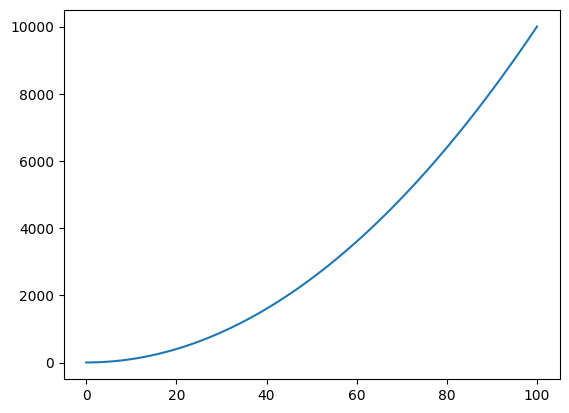

In [34]:
import matplotlib.pyplot as plt

x = np.linspace(0., 100., 100)
y = x**2 + 1.

plt.figure()
plt.plot(x, y)
plt.show()

`plot()` takes two vectors `x` and `y` as inputs (they must have the same size) and plots them against each other. It is standard to define the x-axis with `np.linspace()` if you just want to plot a function. 100 points is usually a good choice, but you can experiments with less points.

The call to `plt.show()` is obligatory at the end to display the window when using a script (very common mistake to forget it!). It is not needed in Jupyter notebooks as it is implicitly called, but let's take the habit anyway.

The call to `plt.figure()` is also optional, as a new figure is created when you call `plt.plot()` for the first time.

**Q:** Create a third vector `z` (e.g. `z = -x**2 + 2`) and plot it against `x` right after `y` (i.e. between `plt.plot(x, y)` and `plt.show()`). What happens?

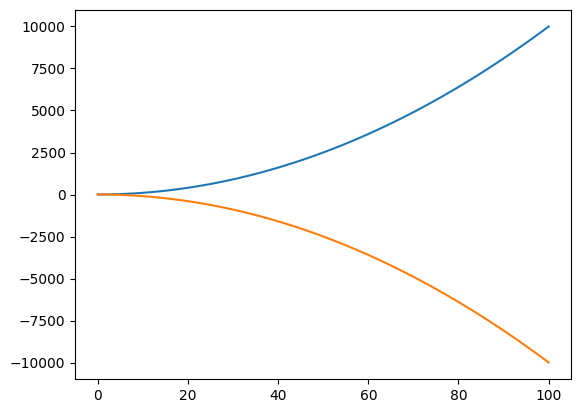

In [35]:
z = -x**2 + 2

plt.plot(x, y)
plt.plot(x, z)

plt.show()

**Q:** Now call `plt.figure()` again between the two plots. What happens?

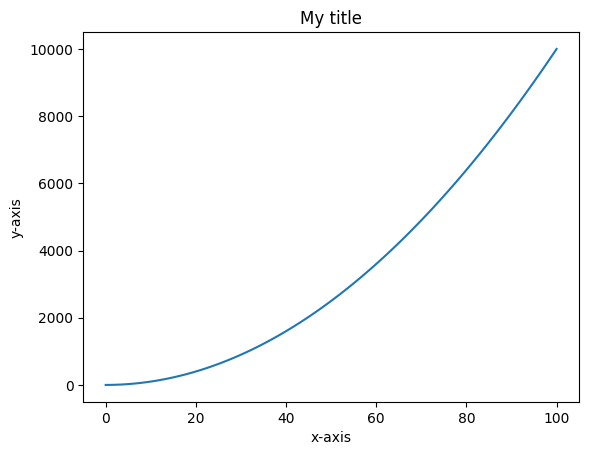

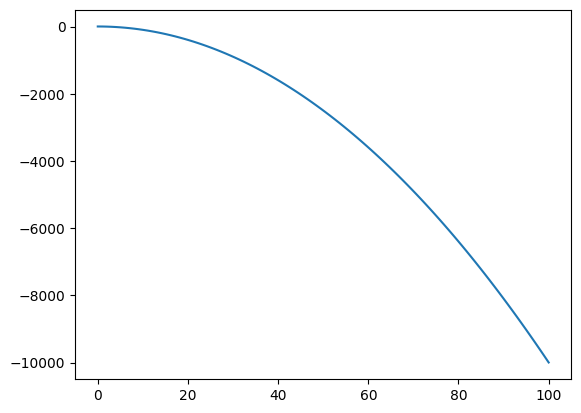

In [41]:
plt.title('My title')
plt.xlabel('x-axis')
plt.ylabel('y-axis')

plt.plot(x, y)
plt.figure() # 两条曲线分开画，画到 两张图里

plt.plot(x, z)

plt.show()

By default, the plot is quite empty. This is fine when experimenting in a notebook, but not when incorporating the figures in your thesis. You can make a plot look better by adding a title, labels on the axes, etc.

```python
plt.title('My title')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
```

**Q:** Make the previous plots nicer by adding legends and axes.

*Hint:* if you know LateX equations, you can insert simple formulas in the title or axes by using two dollar signs `$$`.

In [ ]:
plt.title('My title')
plt.xlabel('x-axis')
plt.ylabel('y-axis')


If you make multiple plots on the same figure by calling `plt.plot()` multiple times, you can add a label to each plot to create a legend with `plt.legend()`:

```python
plt.plot(x, y, label='y')
plt.plot(x, z, label='z')
plt.legend()
```

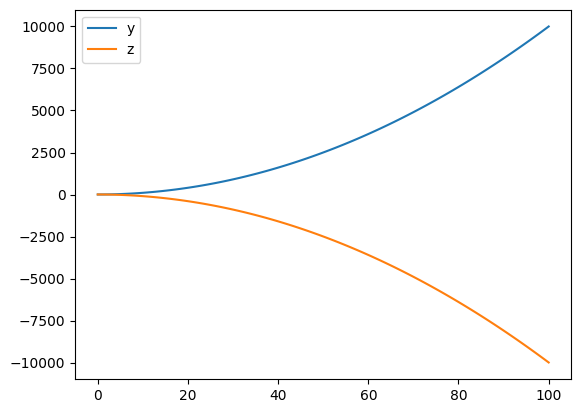

In [39]:
plt.plot(x, y, label='y')
plt.plot(x, z, label='z')

plt.legend()
plt.show()

Another advantage of declaring a figure is that you can modify its size (which is very small in a notebook by default) with the `figsize` argument in inches:

```python
plt.figure(figsize=(16, 10))
```

**Q:** Experiment with figure sizes.

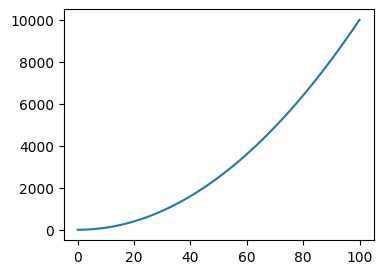

In [47]:
plt.figure(figsize=(4, 3))


plt.plot(x, y)

plt.show()

### Side-by-side plots

To make separate plots in the same figure, you can use `plt.subplot(abc)`.

The function takes three digits a, b, c as input (e.g. 221 or 122) where:

- a is the number of rows.
- b is the number of columns.
- c is the index (starting at 1) of the current subplot.

Here is a dummy example of a 2x2 grid of plots:

```python
plt.subplot(221)
plt.plot(x, y)

plt.subplot(222)
plt.plot(x, z)

plt.subplot(223)
plt.plot(y, x)

plt.subplot(224)
plt.plot(z, x)
```

**Q:** Try it.

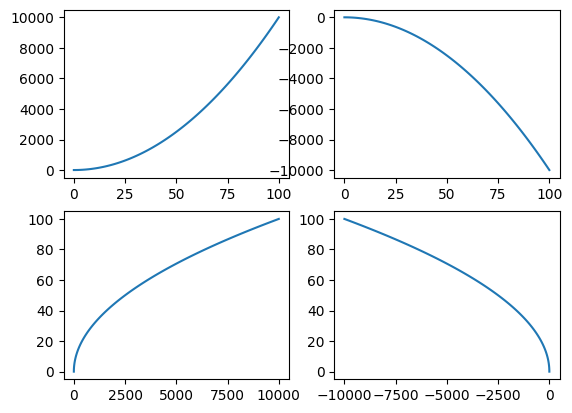

In [54]:
plt.subplot(221)
plt.plot(x, y)

plt.subplot(222)
plt.plot(x, z)

plt.subplot(223)
plt.plot(y, x)

plt.subplot(224)
plt.plot(z, x)

plt.show()

### `plt.imshow()`

Matrices can be displayed using `plt.imshow()`. You can choose the color code with the `cmap` argument (e.g. `gray` or `hot`).

```python
plt.imshow(A, cmap=plt.cm.hot, interpolation='nearest')
plt.colorbar()
```

`plt.colorbar()` allows to show a vertical bar indicating the color code.

The interpolation method can also be selected for small matrices (`'nearest` by default, but you can choose `interpolation="bicubic"` for a smoother display).

(0, 0) is at the top-left of the image, the first axis is vertical. Change it with the `origin` parameter.

**Q:** Create a 10x10 matrix (e.g. randomly) and plot it. Try different color maps (<https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html> and interpolation methods.

[[ 6  8  6  4  1  7  3  1  2  3]
 [ 2  6  9  6  1  3  8  1  3  9]
 [ 3  5  8 10  4  1  9  8  8  9]
 [10  5  5  1  5  2  9  8 10  3]
 [10  8  8  9  1 10  3  3  4  7]
 [ 4  5  5  2  7  3  5  3  9  9]
 [ 4  2 10  2  1  6  9  2  6  2]
 [ 4  2  4  9 10  8  6  5  7  8]
 [ 6  2  6  8  3  9  9  1  3  6]
 [10  8  3  7  6  7  1  4  7  3]]


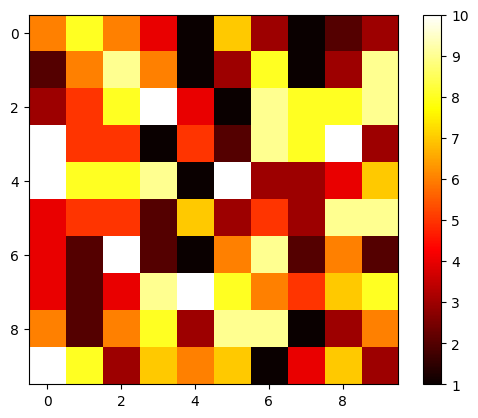

In [63]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

A = rng.integers(1, 11, (10,10)) # random integers
print(A)

plt.imshow(A, cmap=plt.cm.hot, interpolation='nearest')
plt.colorbar()


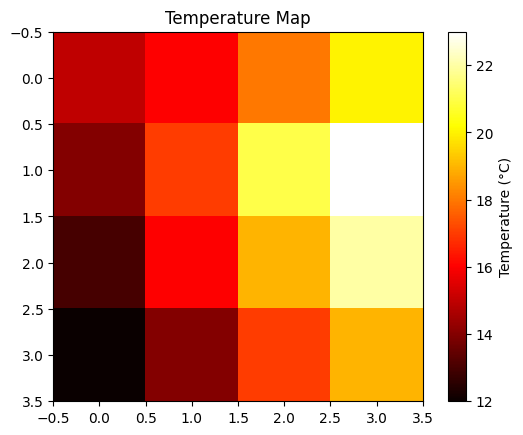

In [64]:
import numpy as np
import matplotlib.pyplot as plt

temperature = np.array([
    [15, 16, 18, 20],
    [14, 17, 21, 23],
    [13, 16, 19, 22],
    [12, 14, 17, 19]
])

plt.imshow(temperature, cmap='hot', interpolation='nearest')
plt.colorbar(label='Temperature (°C)')
plt.title('Temperature Map')
plt.show()

### `plt.scatter()`

If you want to display dots instead of of lines or pixels, `plt.scatter` takes two vectors of same size and plots them against each other:

```python
plt.scatter(x, y)
```

**Q:** Create two vectors with 100 elements and make a scatter plot.

[11 17 44 62 89 76 63 58  3 50 23 94 51 11 37 37 81 55 63 73 36  1 15 24
 52 78 17 75 63 98 37 86 21 98 12 29 68 86 82 75 70 80 13 91 24 45 56 43
 88 72  3 38 26 43 31 65 86 50 58 62 49 85 56 12 54 41 11 92  6 24 80 42
 79  7 52 91 69  9 31 70 72 78  2 22 95  5 86 64 26 83 94 32 46 56 55  8
 16 29 80 84]
[73 13 31  6 69 41 82 30  7  0 37 82 80 78 65 51 15 67 12 20 87 56 73  8
  4 43 29 80 71 57 18 67  2 81 73 75 44 63 58 70 63 92 25 13 44 59 43 67
  9  6 70 95 64 12 62  5 12 59 18 29  1 20  9 78  6 21 77 36 77 88  8 28
 22 25 81 43 39  8 54 35 47 32 43 49 48 37 97 15  7 23 60 50 15 73 31  1
 21 41 49 89]


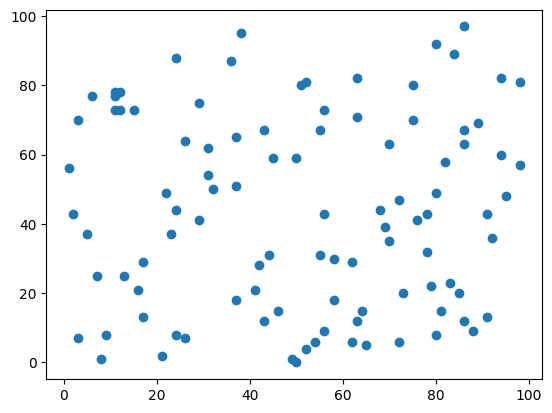

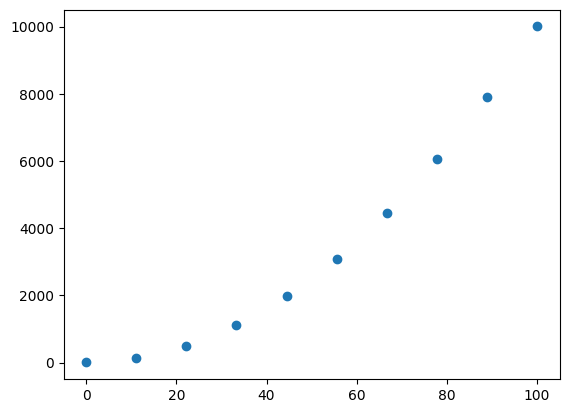

In [80]:
import numpy as np
import matplotlib.pyplot as plt


#A = rng.choice(np.arange(1, 101), size=100)
#B = rng.choice(np.arange(1, 101), size=100)

A = rng.integers(100, size=100)
B = rng.integers(100, size=100)

print(A, B, sep='\n')

plt.scatter(A, B)

plt.figure()
x = np.linspace(0., 100., 10)
y = x**2 + 1.
plt.scatter(x, y)


plt.show()



### `plt.hist()`

Histograms can be useful to visualize the distribution of some data. If `z` is a vector of values, the histogram is simply:

```python
plt.hist(z, bins=20)
```

The number of bins is 10 by default, but you can of course change it.

**Q:** Draw 1000 values from a normal distribution of your choice and make an histogram.

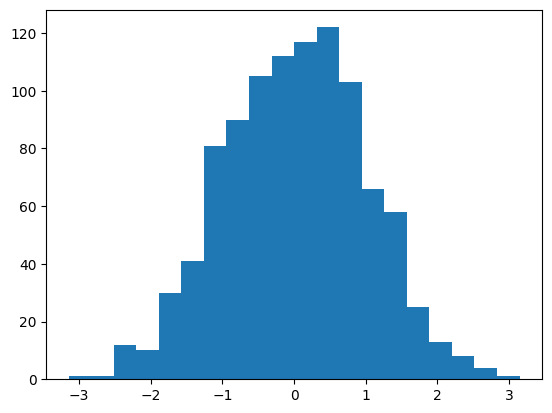

In [84]:
rng = np.random.default_rng()

z = rng.normal(0, 1, 1000)

plt.hist(z, bins=20)
plt.show()

### Try a different plot type
Visit the overview page and try one out.

<https://matplotlib.org/stable/plot_types/index.html>